# Семинар 3. Векторные представления слов и текстов

### План семинара
1. Обучим Word2Vec на вопросах Quora и посмотрим на соседей слов
2. Разберёмся, что FastText делает с редкими словами
3. Соберём вектор целого вопроса из векторов слов
4. Сравним результат с современной статической моделью

На прошлом занятии мы представляли тексты с помощью Bag-of-Words и TF-IDF. У каждого слова был свой столбец, а сходство текстов зависело от общих слов и сочетаний. Но как нам учесть, что слова могут быть связаны по смыслу и синонимичны?

Сегодня мы будем обучать **эмбеддинги слов** - плотные векторы, которые отражают их употребление в корпусе.

In [ ]:
%pip install -q "gensim==4.4.0" "nltk==3.9.2" "bokeh==3.4.3" "sentence-transformers==5.1.2" "transformers==4.57.6"

In [ ]:
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from nltk.tokenize import WordPunctTokenizer
from gensim.models import Word2Vec, FastText
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

SEED = 13
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

## Посмотрим сначала на вопросы

Возьмём корпус Quora - вопросы пользователей на английском языке. Идею позаимствуем из [семинара ШАДа по эмбеддингам](https://github.com/yandexdataschool/nlp_course/blob/2026/week01_embeddings/seminar.ipynb).

В файле одна строка соответствует одному вопросу. Меток в этот раз у нас нет, но для обучения Word2Vec они и не нужны: примеры для предсказания слов мы получим из самих текстов.

In [ ]:
url = "https://www.dropbox.com/s/obaitrix9jyu84r/quora.txt?dl=1"

# кавычки и слово null здесь могут быть частью настоящего вопроса
raw = pd.read_csv(url, sep="\t", header=None, names=["text"],
                  quoting=3, keep_default_na=False)
raw.insert(0, "id", raw.index)
print(f"Вопросов: {len(raw):,}")
raw.loc[[32, 49, 90928], ["id", "text"]]

Вопросов: 537,272


,id,text
32,32,Are Asian girls attracted to black guys?
49,49,Should cricket be our national sport and not hockey?
90928,90928,How do blockchains work?


Сейчас гам потребуется только 100 тысяч из вопросов. Точные повторы уберём, исходные номера строк сохраним в `id`.

Оставим знакомый `WordPunctTokenizer`: он разделяет слова и пунктуацию. Переведём текст в нижний регистр. При этом стоп-слова и окончания пока сохраняем: они тоже задают окружение слова.

In [ ]:
df = raw.drop_duplicates("text").sample(100_000, random_state=SEED).reset_index(drop=True)
tokenizer = WordPunctTokenizer()
data_tok = df["text"].str.lower().map(tokenizer.tokenize).tolist()

print(df.loc[0, "text"])
print(data_tok[0])

What are some examples of isotopes?
['what', 'are', 'some', 'examples', 'of', 'isotopes', '?']


In [ ]:
word_counts = Counter(word for words in data_tok for word in words)
pd.Series({
    "Вопросов": len(df),
    "Всего токенов": sum(word_counts.values()),
    "Разных токенов": len(word_counts),
    "Токенов с частотой от 5": sum(count >= 5 for count in word_counts.values()),
})

Вопросов                    100000
Всего токенов              1326755
Разных токенов               40564
Токенов с частотой от 5      11585
dtype: int64

## Обучим Word2Vec

Предположим, два слова часто встречаются в похожих окружениях. Например, о разных языках программирования могут спрашивать, как их выучить и где найти курсы. Такое сходство контекстов можно использовать, чтобы получить близкие векторы слов.

**Word2Vec** обучает векторы через задачу предсказания слов. У него есть два варианта:

- **CBOW**: по словам контекста предсказываем центральное слово;
- **Skip-gram**: по центральному слову предсказываем слова его контекста.

Во время обучения значения векторов меняются так, чтобы модель лучше справлялась с этим предсказанием. После обучения мы будем использовать полученные векторы для сравнения слов.

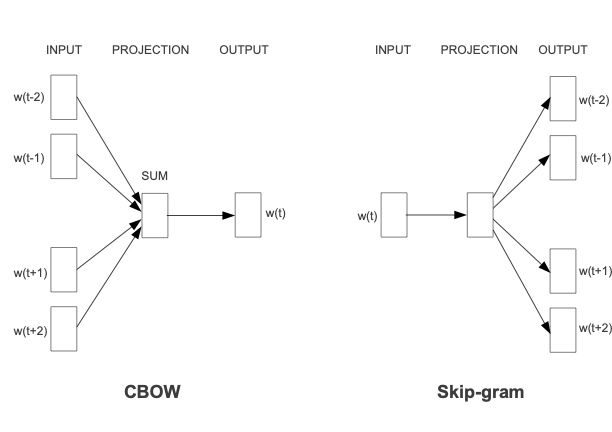

[Источник](https://arxiv.org/pdf/1301.3781v3).

Начнём с CBOW. В gensim за выбор отвечает параметр `sg`: 0 - CBOW, 1 - Skip-gram.

In [ ]:
w2v = Word2Vec(
    sentences=data_tok,
    vector_size=64, # число координат вектора слова
    window=5, # максимальное расстояние до слова контекста
    min_count=5, # редкие токены не включаем в словарь
    sg=0, # обучаем cbow
    negative=5, # число шумовых примеров при обучении
    epochs=10, # число проходов по корпусу
    workers=1,
    seed=SEED,
)

print("Размер таблицы векторов:", w2v.wv.vectors.shape)

Размер таблицы векторов: (11585, 64)


Получилась таблица векторов, где каждому слову из словаря соответствует строка из 64 чисел. В gensim она хранится в `w2v.wv`.

Теперь посмотрим на первые координаты слова, например, `python`. Значения этих координат модель подобрала при обучении. Информация об употреблении слова распределена по всему вектору.

In [ ]:
pd.Series(w2v.wv["python"][:8], name="Первые 8 координат")

0    0.158673
1    1.002970
2    0.290433
3    0.460231
4    1.264353
5    0.523812
6   -0.054997
7    0.321457
Name: Первые 8 координат, dtype: float32

### Кто оказался рядом?

Теперь найдём слова с похожими векторами. Будем сравнивать их по **косинусной близости**: чем ближе направления двух векторов, тем больше её значение. В gensim такой поиск выполняет `most_similar`.

Возьмём `python` и `anything`

In [ ]:
for word in ["python", "anything"]:
    print(word)
    display(pd.DataFrame(w2v.wv.most_similar(word, topn=6),
                         columns=["Сосед", "Косинус"]).round(3))

python


,Сосед,Косинус
0,javascript,0.916
1,php,0.889
2,java,0.875
3,html,0.858
4,css,0.820
5,c,0.818


anything


,Сосед,Косинус
0,something,0.867
1,everything,0.760
2,nothing,0.751
3,him,0.649
4,everyone,0.643
5,others,0.615


Word2Vec учится на окружении слов. Даже слова с противоположными значениями могут встречаться в похожих контекстах и получать близкие векторы.

Чтобы понять результат для `python`, вернёмся к вопросам, на которых обучали модель. Давайте посмотрим, в каких значениях там используется это слово

In [ ]:
word = "python"
has_word = [word in words for words in data_tok]
df.loc[has_word, ["id", "text"]].head(4)

,id,text
962,33270,How can I do N- queens problem using genetic algorithm implementation in Python?
1577,202219,"What are some good, free resources to learn Python 3?"
1765,352694,"Which is the best programming language to learn in today's era? Java, C,C++, Python or any else?"
2108,65778,What are the best python online courses for beginners?


**Задание 1. Объясните соседей**

Выберите слово из словаря модели. Можно начать с `bank`, `good` или взять своё.

1. Найдите его ближайших соседей и несколько вопросов, где оно встречается. Для вопросов поменяйте `word` в ячейке выше.
2. Какие общие темы или конструкции могли сблизить эти слова?
3. Все ли найденные слова могут заменить выбранное слово без изменения смысла?

Обоснуйте ответ примерами из корпуса.

In [ ]:
word = "bank"
pd.DataFrame(w2v.wv.most_similar(word, topn=6),
             columns=["Сосед", "Косинус"]).round(3)

,Сосед,Косинус
0,sbi,0.834
1,icici,0.790
2,account,0.771
3,savings,0.767
4,debit,0.752
5,credit,0.731


**Ваш ответ:**

### Посмотрим на векторы

Вектор каждого слова содержит 64 координаты. Чтобы показать слова на плоскости, сократим размерность до двух с помощью PCA.

Возьмём `python`, `bank`, `university` и их ближайших соседей. Перед проекцией нормируем векторы. Цвет обозначит, для какого исходного слова мы нашли соседей.

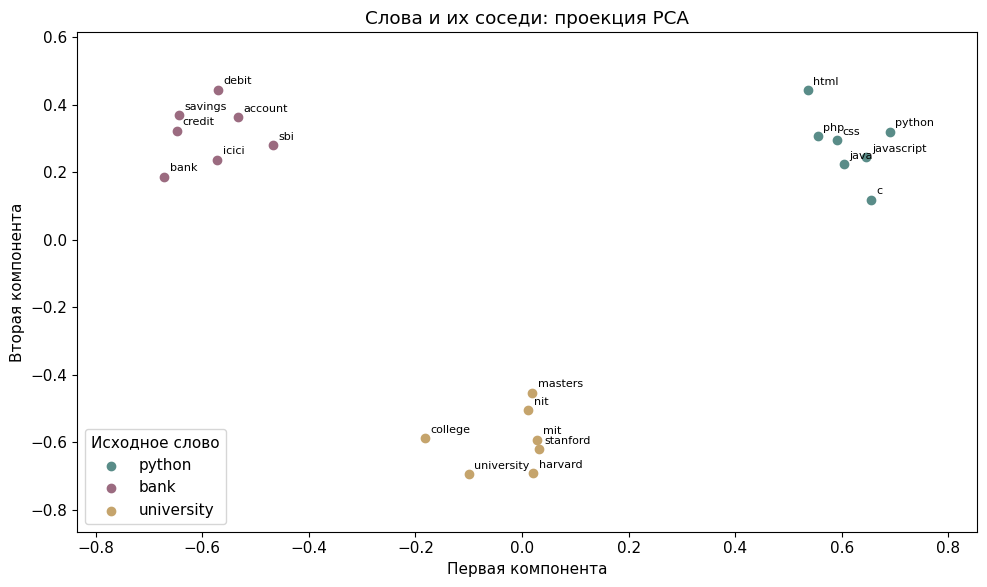

In [ ]:
groups = {}
for word in ["python", "bank", "university"]:
    groups[word] = word
    for neighbor, score in w2v.wv.most_similar(word, topn=6):
        groups.setdefault(neighbor, word)

plot_words = list(groups)
vectors = normalize(w2v.wv[plot_words])
pca = PCA(n_components=2)
coordinates = pca.fit_transform(vectors)
plot_df = pd.DataFrame(coordinates, columns=["x", "y"])
plot_df["word"] = plot_words
plot_df["group"] = [groups[word] for word in plot_words]

colors = {"python": "#598c88", "bank": "#9b6b80", "university": "#c5a46c"}
fig, ax = plt.subplots(figsize=(10, 6))
for group, color in colors.items():
    part = plot_df[plot_df["group"].eq(group)]
    ax.scatter(part["x"], part["y"], c=color, label=group)
for row in plot_df.itertuples():
    ax.annotate(row.word, (row.x, row.y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set(xlabel="Первая компонента", ylabel="Вторая компонента", title="Слова и их соседи: проекция PCA")
ax.margins(x=0.12, y=0.15)
ax.legend(title="Исходное слово")
plt.tight_layout()
plt.show()

PCA сокращает 64 координаты до двух, поэтому взаимное расположение слов меняется. Близость двух точек на плоскости можно сопоставить с косинусом их исходных векторов.

## FastText и редкие слова

У Word2Vec отдельный вектор есть только у слов из его словаря. Мы поставили `min_count=5`, поэтому слова, встретившиеся реже пяти раз, в него не попали.

В вопросе `How do blockchains work?` редкое слово `blockchains` задаёт тему. Посмотрим, сколько раз оно встретилось в нашей выборке и попало ли в словарь. Заодно и проверим `unhappiness`.

In [ ]:
rare_words = ["blockchains", "unhappiness"]
display(pd.DataFrame({
    "Слово": rare_words,
    "Частота": [word_counts[word] for word in rare_words],
    "В словаре Word2Vec": [word in w2v.wv.key_to_index for word in rare_words],
}))
df.loc[[any(word in words for word in rare_words) for words in data_tok], ["id", "text"]]

,Слово,Частота,В словаре Word2Vec
0,blockchains,2,False
1,unhappiness,1,False


,id,text
59889,90928,How do blockchains work?
69699,142899,What are the most interesting uses of blockchains other than cryptocurrencies?
94094,330873,How does the rate of student happiness/unhappiness at Yale differ from major to major?


Как получить вектор, если целого слова нет в словаре? **FastText** использует для этого части слов - перекрывающиеся символьные n-граммы. У каждой такой части есть обучаемый вектор. Представление слова строится из векторов его частей, поэтому можно обработать и новое слово, если его части уже встречались при обучении.

Давайте теперь разберем `blockchains` на тройки символов. Добавим `<` и `>` для обозначения границ слова. Такие тройки будут общими для разных слов: например, у `blockchain` и `blockchains` большая часть n-грамм совпадёт.

In [ ]:
word = "blockchains"
marked_word = "<" + word + ">"
[marked_word[i:i + 3] for i in range(len(marked_word) - 2)]

['<bl', 'blo', 'loc', 'ock', 'ckc', 'kch', 'cha', 'hai', 'ain', 'ins', 'ns>']

Обучим FastText на той же выборке, сохранив основные настройки Word2Vec. В примере выше мы рассматривали только тройки символов, а модель будет использовать n-граммы длиной от 3 до 6. Подробности есть в [описании FastText](https://fasttext.cc/docs/en/unsupervised-tutorial.html).

В FastText символьные n-граммы **перекрываются**, а их векторы затем объединяются в вектор целого слова.

In [ ]:
ft = FastText(
    sentences=data_tok,
    vector_size=64,
    window=5,
    min_count=5,
    sg=0,
    negative=5,
    epochs=10,
    workers=1,
    seed=SEED,
    min_n=3,
    max_n=6,
    bucket=200_000, # ограничиваем размер таблицы символьных n-грамм
)

print("blockchains в словаре:", "blockchains" in ft.wv.key_to_index)
print("Размер полученного вектора:", ft.wv["blockchains"].shape)

blockchains в словаре: False
Размер полученного вектора: (64,)


In [ ]:
for word in rare_words:
    print(word)
    display(pd.DataFrame(ft.wv.most_similar(word, topn=5),
                         columns=["Сосед FastText", "Косинус"]).round(3))

blockchains


,Сосед FastText,Косинус
0,blockchain,0.895
1,blocks,0.863
2,deletes,0.828
3,contains,0.815
4,fingerprints,0.807


unhappiness


,Сосед FastText,Косинус
0,happiness,0.958
1,sadness,0.900
2,loneliness,0.893
3,ingress,0.882
4,fairness,0.880


Теперь у `blockchains` есть вектор, хотя в словарь FastText это слово тоже не попало.

Ближайшим соседом `unhappiness` оказалось `happiness`. У этих слов много общих n-грамм, но приставка `un-` меняет значение на противоположное. Метод дает им близкие векторы, поэтому одной близости недостаточно, чтобы различить эти значения.

**Задание 2. Найдите ещё один случай**

Ниже собраны редкие слова из нашей выборки. Выберите одно, прочитайте вопрос с ним и получите соседей FastText. Какие части написания у них совпадают? Насколько близки их значения в контексте вопроса?

In [ ]:
rare = [word for word, count in word_counts.items()
        if 0 < count < 5 and word.isalpha() and len(word) >= 7]
rare[:20]

['nepalese',
 'metering',
 'specialising',
 'commitments',
 'chiseled',
 'jawline',
 'cheekbones',
 'universally',
 'demonic',
 'hamburg',
 'postnatal',
 'preprocessors',
 'virtusa',
 'jamestown',
 'ventilation',
 'informal',
 'defaults',
 'perpetrating',
 'teammates',
 'befriend']

In [ ]:
word = "preprocessors"
display(df.loc[[word in words for words in data_tok], ["id", "text"]])
pd.DataFrame(ft.wv.most_similar(word, topn=5),
             columns=["Сосед FastText", "Косинус"]).round(3)

,id,text
39,111070,What are the preprocessors in C programming?


,Сосед FastText,Косинус
0,processors,0.941
1,processes,0.887
2,predators,0.879
3,procedures,0.841
4,professors,0.830


**Ваш ответ:**

## От слова к вопросу

Теперь попробуем применить векторы к поиску. Представим, что пользователь задал вопрос, а мы хотим показать ему похожие вопросы из нашей коллекции.

Для сравнения нужен один вектор на весь вопрос. Самый простой способ - это взять векторы его слов и усреднить их по каждой координате. Сколько бы слов ни было в вопросе, результат будет содержать те же 64 числа.

$$\mathbf z(x)=\frac{1}{m}\sum_{i=1}^{m}\mathbf e(t_i),$$

где $t_i$ - токены, для которых есть вектор, а $m$ - их количество.

Если известных токенов не оказалось, вернём нулевой вектор.

Для нашей задачи поиска возьмем 20 тысяч вопросов. Полученные ненулевые векторы нормируем до единичной длины, чтобы дальше считать косинус через скалярное произведение.

In [ ]:
def mean_word_vector(text):
    words = tokenizer.tokenize(text.lower())
    known = [word for word in words if word in w2v.wv.key_to_index]
    if not known:
        return np.zeros(w2v.vector_size, dtype=np.float32)
    return w2v.wv[known].mean(axis=0)

catalog = df.sample(20_000, random_state=SEED).reset_index(drop=True)
catalog["text_key"] = catalog["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
mean_vectors = normalize(np.array([mean_word_vector(text) for text in catalog["text"]]))
print("Размер матрицы вопросов:", mean_vectors.shape)
print("Нулевых векторов:", np.count_nonzero(np.linalg.norm(mean_vectors, axis=1) == 0))

Размер матрицы вопросов: (20000, 64)
Нулевых векторов: 0


Выберем один вопрос и сравним его вектор со всеми остальными. Три вопроса с наибольшим косинусом попадут в результат поиска.

Начнём сейчас с вопроса о выборе ноутбука.

In [ ]:
def nearest_questions(query_id, vectors, topn=3):
    position = catalog.index[catalog["id"].eq(query_id)][0]
    scores = vectors @ vectors[position]  # векторы уже нормированы
    same_text = catalog["text_key"].eq(catalog.loc[position, "text_key"])
    scores[same_text.to_numpy()] = -np.inf
    nearest = np.argsort(scores)[-topn:][::-1]
    result = catalog.loc[nearest, ["id", "text"]].copy()
    result["Косинус"] = scores[nearest]
    result.index = range(1, len(result) + 1)
    return result.round(3)

query_id = 503631
print(catalog.loc[catalog["id"].eq(query_id), "text"].iloc[0])
nearest_questions(query_id, mean_vectors)

Which are the best laptops under 40000?


,id,text,Косинус
1,333091,Which are the best fitness bands?,0.960
2,440898,Which are the best cough lozenges?,0.956
3,271280,Which are the best weekend getaways near Kolkata?,0.954


Для вопроса о ноутбуках нашлись вопросы о фитнес-браслетах, пастилках от кашля и поездках на выходные.

У этих вопросов общая конструкция вопроса. Возможно, её вклад оказался слишком сильным. Но сначала проверим более простое объяснение: **не потеряли ли мы laptops при усреднении** из-за отсутствия слова в словаре?

In [ ]:
query = catalog.loc[catalog["id"].eq(query_id), "text"].iloc[0]
query_tokens = tokenizer.tokenize(query.lower())
pd.DataFrame({
    "Токен": query_tokens,
    "Есть вектор": [word in w2v.wv.key_to_index for word in query_tokens],
    "Частота в обучающем корпусе": [word_counts[word] for word in query_tokens],
})

,Токен,Есть вектор,Частота в обучающем корпусе
0,which,True,5345
1,are,True,18215
2,the,True,47106
3,best,True,7668
4,laptops,True,39
5,under,True,444
6,40000,True,5
7,?,True,103103


Все токены запроса вошли в среднее, а значит, наличие векторов для всех слов вопроса само по себе не решило проблему.

При усреднении вклад вносят все токены, в том числе вопросительные слова и пунктуация, а порядок слов теряется. Кроме того, Word2Vec обучался предсказывать окружение отдельных слов. Сходство целых вопросов мы при обучении не задавали.

Нам бы проверить такую модель, которую специально обучали для поиска по текстам.

## Современная статическая модель

Поработаем с моделью, обученной на парах текстов для поиска. Она тоже усредняет векторы токенов, но при обучении эти векторы подбираются так, чтобы запрос и подходящий ему текст получали близкие представления.

Так устроена [static-retrieval-mrl-en-v1](https://huggingface.co/sentence-transformers/static-retrieval-mrl-en-v1), выпущенная командой Sentence Transformers в 2025 году. Возьмём её готовые веса и сравним поиск со средним Word2Vec.

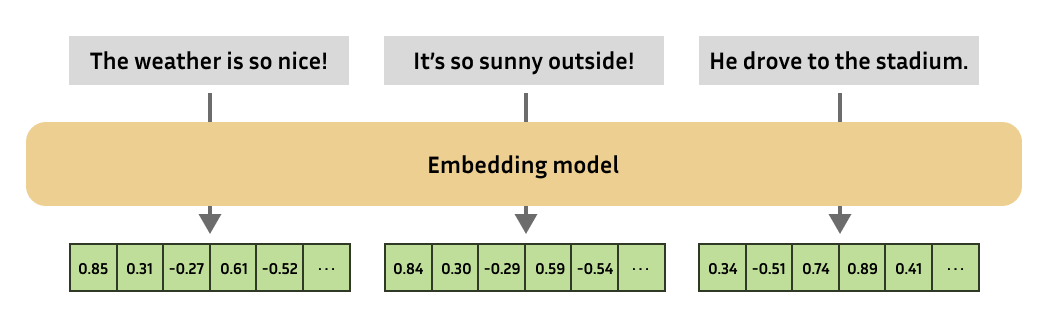

Источник - [Sentence Transformers, 2025](https://huggingface.co/blog/static-embeddings).

В **статической модели** у каждого токена один фиксированный вектор, который не меняется от вопроса к вопросу. Чтобы получить представление текста, модель выбирает нужные строки таблицы и усредняет их.

У готовой модели есть свой субсловный токенизатор. Поэтому передадим ей исходные вопросы, а он уже сам разобьет их на токены. Дополнительную лемматизацию и удаление стоп-слов здесь делать не будем.

In [ ]:
from sentence_transformers import SentenceTransformer

static_model = SentenceTransformer(
    "sentence-transformers/static-retrieval-mrl-en-v1",
    device="cpu",
)
static_model

SentenceTransformer(
  (0): StaticEmbedding(
    (embedding): EmbeddingBag(30522, 1024, mode='mean')
  )
)

Вернёмся к вопросу `How do blockchains work?` и посмотрим, как его обработает токенизатор готовой модели.

Здесь используется WordPiece. Он разбивает слово на последовательность частей, а знак `##` обозначает продолжение слова. Это позволит представить `blockchains` через субтокены из готового словаря.

In [ ]:
text = df.loc[df["id"].eq(90928), "text"].iloc[0]
print(text)
static_model[0].tokenizer.encode(text, add_special_tokens=False).tokens

How do blockchains work?


['how', 'do', 'block', '##chai', '##ns', 'work', '?']

In [ ]:
static_vectors = static_model.encode(
    catalog["text"].tolist(),
    batch_size=256,
    normalize_embeddings=True, # для поиска через скалярное произведение
    show_progress_bar=False,
)
print("Размер матрицы вопросов:", static_vectors.shape)

Размер матрицы вопросов: (20000, 1024)


`EmbeddingBag` с режимом mean выбирает векторы токенов из таблицы и усредняет их. После вызова encode мы получаем матрицу: одна строка на вопрос, 1024 координаты в строке.

Сравним теперь два способа на одних и тех же запросах. Коллекция вопросов и правило поиска остаются прежними, меняются их векторы.

In [ ]:
for query_id in [503631, 315735, 383680]:
    print(catalog.loc[catalog["id"].eq(query_id), "text"].iloc[0])
    display(pd.concat({
        "Среднее Word2Vec": nearest_questions(query_id, mean_vectors),
        "Static 2025": nearest_questions(query_id, static_vectors),
    }, names=["Представление", "Место"]))

Which are the best laptops under 40000?


id  \
Представление    Место           
Среднее Word2Vec 1      333091   
                 2      440898   
                 3      271280   
Static 2025      1      326347   
                 2      312346   
                 3      348652   

                                                                     text  \
Представление    Место                                                      
Среднее Word2Vec 1                      Which are the best fitness bands?   
                 2                     Which are the best cough lozenges?   
                 3      Which are the best weekend getaways near Kolkata?   
Static 2025      1                  What are the best laptops around 50k?   
                 2                    What is the best laptop under €600?   
                 3                 What is the best laptop for a student?   

                        Косинус  
Представление    Место           
Среднее Word2Vec 1        0.960  
                 2        0.956  
                 3        0.954  
Static 2025      1        0.687  
                 2        0.680  
                 3        0.680

How do I can improve English speaking?


id  \
Представление    Место           
Среднее Word2Vec 1       86469   
                 2      528816   
                 3       55773   
Static 2025      1       86469   
                 2      449763   
                 3      285439   

                                                                                                                      text  \
Представление    Место                                                                                                       
Среднее Word2Vec 1                                                             How can I do learn speaking English easily?   
                 2                                                                      How can I practise spoken English?   
                 3                                              How can I improve my own understanding of English grammar?   
Static 2025      1                                                             How can I do learn speaking English easily?   
                 2                                                                      How do I use in and at in English?   
                 3      How should I Improve my English speaking to speak fluently in front of other can anyone suggested?   

                        Косинус  
Представление    Место           
Среднее Word2Vec 1        0.966  
                 2        0.945  
                 3        0.914  
Static 2025      1        0.787  
                 2        0.674  
                 3        0.674

What are some interesting Amazon India hacks to save money?


id  \
Представление    Место           
Среднее Word2Vec 1      461720   
                 2        8287   
                 3      454319   
Static 2025      1      389883   
                 2      323886   
                 3       70375   

                                                                          text  \
Представление    Место                                                           
Среднее Word2Vec 1                 What are the top ways to make money online?   
                 2             What are some ways to make money doing nothing?   
                 3       What are some ways to cheaply protect business ideas?   
Static 2025      1              What are some interesting psychological hacks?   
                 2                                              How do I hack?   
                 3      What are some interesting hacks for Microsoft Outlook?   

                        Косинус  
Представление    Место           
Среднее Word2Vec 1        0.871  
                 2        0.868  
                 3        0.856  
Static 2025      1        0.609  
                 2        0.581  
                 3        0.547

У готовой модели для вопроса о ноутбуках все три результата тоже относятся к ноутбукам. Однако в найденных вопросах встречаются другие бюджеты и требования. Для запроса об английской речи обе модели находят вопросы о разговорной практике.

**Задание 3. Подходит ли найденный вопрос?**

Выберите другой запрос и сравните результаты двух моделей. Какие из найденных вопросов вы бы показали пользователю? Где совпала задача, а где только тема или отдельные слова?

In [ ]:
# выберите id из этой таблицы и подставьте его в ячейку ниже
catalog.sample(6, random_state=SEED)[["id", "text"]]

,id,text
10138,96979,Is Ram Gopal Verma the best ever movie director of India?
15088,500971,What are some of the best plagiarism detection software available?
19626,161709,To what extent do you think a Business can control the demand for its products?
1922,514371,Is there a picture or a police sketch of what Cotton Eye Joe really looks like?
989,106660,Which are the best certification programs for finance professionals?
5675,499725,Gate 2019 : which one is better Rabindrababu Ravula Sir's online course or Made easy Kolkata?


In [ ]:
query_id = 315735
print(catalog.loc[catalog["id"].eq(query_id), "text"].iloc[0])
display(nearest_questions(query_id, mean_vectors))
display(nearest_questions(query_id, static_vectors))

How do I can improve English speaking?


,id,text,Косинус
1,86469,How can I do learn speaking English easily?,0.966
2,528816,How can I practise spoken English?,0.945
3,55773,How can I improve my own understanding of English grammar?,0.914


,id,text,Косинус
1,86469,How can I do learn speaking English easily?,0.787
2,449763,How do I use in and at in English?,0.674
3,285439,How should I Improve my English speaking to speak fluently in front of other can anyone suggested?,0.674


**Ваш ответ:**

## Дополнительно: давайте уменьшим размерность

У готовой модели вектор текста содержит 1024 координаты. Для большой коллекции хранение таких векторов может занимать много памяти. А что будет, если оставить только первые 256?

Выбранная модель обучалась у нас с **Matryoshka Loss** - это когда ошибка учитывалась и для полного вектора, и для его начальных частей. Поэтому первые 256 координат тоже обучались как представление текста для поиска. У Word2Vec обучение использует вектор целиком.

[Описание Matryoshka в выбранной модели](https://huggingface.co/sentence-transformers/static-retrieval-mrl-en-v1).

Теперь оставим 256 координат, снова нормируем векторы и сравним ближайшие вопросы.

In [ ]:
# после обрезки снова нормируем оба представления: запрос и каталог
small_vectors = normalize(static_vectors[:, :256].copy())
pd.DataFrame({
    "Координат": [static_vectors.shape[1], small_vectors.shape[1]],
    "Память матрицы, МиБ": [static_vectors.nbytes / 2**20, small_vectors.nbytes / 2**20],
}, index=["Полный вектор", "Первые 256 координат"]).round(2)

,Координат,"Память матрицы, МиБ"
Полный вектор,1024,78.12
Первые 256 координат,256,19.53


In [ ]:
query_id = 503631
display(pd.concat({
    "1024 координаты": nearest_questions(query_id, static_vectors, topn=5),
    "256 координат": nearest_questions(query_id, small_vectors, topn=5),
}, names=["Представление", "Место"]))

id  \
Представление   Место           
1024 координаты 1      326347   
                2      312346   
                3      348652   
                4      154875   
                5      248285   
256 координат   1      154875   
                2      348652   
                3      312346   
                4      326347   
                5      248285   

                                                                                          text  \
Представление   Место                                                                            
1024 координаты 1                                        What are the best laptops around 50k?   
                2                                          What is the best laptop under €600?   
                3                                       What is the best laptop for a student?   
                4                              Which is the best laptop in India under 50,000?   
                5      What is the best laptop to buy up to Rs 40000 with a good graphic card?   
256 координат   1                              Which is the best laptop in India under 50,000?   
                2                                       What is the best laptop for a student?   
                3                                          What is the best laptop under €600?   
                4                                        What are the best laptops around 50k?   
                5      What is the best laptop to buy up to Rs 40000 with a good graphic card?   

                       Косинус  
Представление   Место           
1024 координаты 1        0.687  
                2        0.680  
                3        0.680  
                4        0.677  
                5        0.654  
256 координат   1        0.725  
                2        0.721  
                3        0.699  
                4        0.678  
                5        0.671

Матрица векторов вопросов занимает в четыре раза меньше памяти: 19.53 МиБ вместо 78.12 МиБ. Размер самой модели при этом не изменился.

Для запроса про ноутбуки состав первых пяти результатов совпал, только их порядок изменился.

**Задание 4. Сколько координат оставить?**

Сравните результаты ещё для двух запросов.

**Ваш ответ:**

### И ещё одна визуализация: где находятся соседи слова?

На первом рисунке мы заранее выбрали три группы слов. Теперь возьмём 500 частых слов и добавим к ним `python` с пятью ближайшими соседями из полного словаря.

Положение точек получим с помощью PCA, а цвет будет показывать косинусную близость к `python` в исходных 64 координатах. Чем светлее точка, тем больше косинус.

**Вопрос:** все ли точки рядом с запросом на плоскости похожи на него по цвету? Ведь положение после PCA и близость исходных векторов могут давать разное представление о соседстве.

In [ ]:
from bokeh.io import output_notebook, show
from bokeh.models import ColumnDataSource, HoverTool, ColorBar, LinearColorMapper
from bokeh.palettes import Viridis256
from bokeh.plotting import figure
from bokeh.transform import transform

output_notebook(hide_banner=True)
query_word = "python" # можно выбрать и любое другое слово из словаря
neighbors = [word for word, score in w2v.wv.most_similar(query_word, topn=5)]
common_words = [word for word in w2v.wv.index_to_key if word.isalpha()][:500]
words = list(dict.fromkeys(common_words + [query_word] + neighbors))

vectors = normalize(w2v.wv[words])
points = PCA(n_components=2).fit_transform(vectors)
map_df = pd.DataFrame(points, columns=["x", "y"])
map_df["word"] = words
map_df["count"] = [word_counts[word] for word in words]

# близость считаем до проекции на плоскость
map_df["cosine"] = vectors @ w2v.wv.get_vector(query_word, norm=True)
source = ColumnDataSource(map_df)
colors = LinearColorMapper(palette=Viridis256,
                           low=map_df["cosine"].min(), high=1)

plot = figure(width=1000, height=550, active_scroll="wheel_zoom",
              title=f"Соседи слова {query_word}: положение по PCA, цвет по косинусу",
              x_axis_label="Первая компонента", y_axis_label="Вторая компонента")
dots = plot.scatter("x", "y", source=source, size=7, alpha=0.65,
                    color=transform("cosine", colors))
plot.add_tools(HoverTool(renderers=[dots], tooltips=[
    ("Слово", "@word"), ("Частота", "@count"), ("Косинус", "@cosine{0.000}"),
]))

selected = map_df[map_df["word"].isin([query_word] + neighbors)].sort_values("y")
plot.scatter(selected["x"], selected["y"], size=12,
             fill_alpha=0, line_color="#202020", line_width=2)
query = map_df[map_df["word"].eq(query_word)]
plot.scatter(query["x"], query["y"], marker="star", size=22, color="#d6402b")

label_x = map_df["x"].max() + 0.18 * np.ptp(points[:, 0])
label_y = np.linspace(map_df["y"].min(), map_df["y"].max(), len(selected))
plot.segment(selected["x"], selected["y"], label_x, label_y,
             color="#777777", alpha=0.5, line_width=1)
plot.text(x=[label_x] * len(selected), y=label_y, text=selected["word"].tolist(),
          text_font_size="11pt", text_baseline="middle", x_offset=7)
plot.x_range.range_padding = 0.18
plot.add_layout(ColorBar(color_mapper=colors, title=f"Косинус с {query_word}",
                         orientation="horizontal", height=10), "below")
show(plot)
# красивое

## Что по итогу?

- **Word2Vec** обучает векторы слов через предсказание контекста или слова по контексту. Слова с похожим употреблением могут получать близкие векторы, даже если их значения противоположны.
- **FastText** использует символьные n-граммы. Из их векторов можно собрать представление слова, которого нет в словаре модели.
- **Среднее векторов слов** даёт один вектор на текст. При таком усреднении теряется порядок слов, а служебные слова и пунктуация участвуют наравне с остальными токенами.
- **Готовая статическая модель** тоже использует таблицу векторов и усреднение. Её векторы подбирались на парах текстов для задачи поиска.